# 01. Listings EDA

Exploratory analysis of the listings table from the Inside Airbnb Sydney
snapshot used as a structural proxy. No model is trained here and no fitted
statistic is saved. The outputs are figures in `reports/figures/` and a list
of data quality issues with a proposed action for each, which notebook 03
then implements.

Two rules hold throughout:

- Every time window is measured relative to the **snapshot date** taken from
  `last_scraped`, never relative to today. The notebook asserts this.
- Nothing learned from the data (medians, fences, scaler ranges) is written
  anywhere. Those belong to the training split, later.

Sections:

0. Setup
1. Load and integrity summary
2. Price
3. Missingness, empty and constant columns
4. Numeric columns and odd values
5. Categorical columns
6. Price by room type, capacity and neighbourhood
7. Geography and distance to the CBD
8. Correlation with log price
9. Derived parses: amenities, bathrooms, host tenure
10. Data quality issues and proposed actions

## 0. Setup

Paths come from `src.config` so this notebook cannot disagree with the rest of
the pipeline about where data lives. Only folder names are printed, never
absolute paths.

The raw download in this snapshot is plain `.csv`, not `.csv.gz`.
`resolve_raw` accepts either, so the notebook keeps working if the files are
recompressed later.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RAW_DATA_DIR, REPORTS_DIR  # noqa: E402
from src.preprocessing.reviews import REVIEW_SCORE_COLUMNS  # noqa: E402
from src.preprocessing.target import parse_price  # noqa: E402

FIGURE_DIR = REPORTS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9.0, 5.0)
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"


def resolve_raw(stem: str) -> Path:
    """Return the raw file for a stem, accepting .csv or .csv.gz."""
    for suffix in (".csv", ".csv.gz"):
        candidate = RAW_DATA_DIR / f"{stem}{suffix}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"no {stem}.csv or {stem}.csv.gz in the raw data folder")


def save_figure(fig, name: str) -> None:
    """Write a figure under reports/figures and report the relative path."""
    fig.savefig(FIGURE_DIR / f"{name}.png")
    print(f"saved reports/figures/{name}.png")


print(f"project folder : {PROJECT_ROOT.name}")
print("figure folder  : reports/figures")
print(f"listings file  : {resolve_raw('listings').name}")

project folder : pricing-recommendation-system
figure folder  : reports/figures
listings file  : listings.csv


## 1. Load and integrity summary

Row count, column count, dtypes, the snapshot date and duplicate ids. The
snapshot date is read from `last_scraped` and asserted to be single valued,
because every window in notebooks 02 and 03 is anchored to it.

In [2]:
listings = pd.read_csv(resolve_raw("listings"), low_memory=False)
print(f"rows    : {len(listings):,}")
print(f"columns : {listings.shape[1]}")

snapshot_values = sorted(listings["last_scraped"].dropna().unique())
assert len(snapshot_values) == 1, f"last_scraped is not single valued: {snapshot_values}"
SNAPSHOT_DATE = pd.Timestamp(snapshot_values[0])
print(f"\nsnapshot date (last_scraped)   : {SNAPSHOT_DATE.date()}")
print(f"calendar_last_scraped values   : "
      f"{sorted(listings['calendar_last_scraped'].dropna().unique())}")
print(f"scrape_id values               : "
      f"{sorted(listings['scrape_id'].dropna().unique())}")

print(f"\nduplicate ids        : {int(listings['id'].duplicated().sum())}")
print(f"id is unique         : {listings['id'].is_unique}")
print(f"id dtype             : {listings['id'].dtype}")

print("\ndtype counts")
print(listings.dtypes.astype(str).value_counts().to_string())

rows    : 20,833
columns : 90

snapshot date (last_scraped)   : 2026-09-17
calendar_last_scraped values   : ['2026-09-17']
scrape_id values               : [np.int64(20260916052042)]

duplicate ids        : 0
id is unique         : True
id dtype             : int64

dtype counts
float64    39
object     29
int64      22


## 2. Price

`parse_price` from `src.preprocessing.target` strips the currency symbol and
thousands separators. Prices are **AUD** at the snapshot date; no conversion
is applied anywhere in this project.

Both scales are shown because the raw distribution is dominated by a thin
upper tail, which is what motivates fitting on `log1p(price)`.

In [3]:
CURRENCY = "AUD"
DAY1_UPPER_FENCE = 1874.07  # carried over from notebooks/day1_audit_and_selection

price = parse_price(listings["price"])
listings["price_num"] = price
log_price = np.log1p(price)

print(f"rows                 : {len(price):,}")
print(f"price missing        : {int(price.isna().sum()):,} "
      f"({price.isna().mean():.2%})")
print(f"price == 0           : {int((price == 0).sum()):,}")
print(f"price < 0            : {int((price < 0).sum()):,}")
print(f"price usable (> 0)   : {int((price > 0).sum()):,}")

usable = price.loc[price > 0]
print(f"\nprice percentiles ({CURRENCY})")
print(
    usable.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .round(2)
    .to_string()
)
print(f"\nskew raw scale : {usable.skew():.2f}")
print(f"skew log scale : {np.log1p(usable).skew():.2f}")
print(f"\nabove the Day 1 upper fence of {DAY1_UPPER_FENCE:,.2f} {CURRENCY}: "
      f"{int((usable > DAY1_UPPER_FENCE).sum()):,} "
      f"({(usable > DAY1_UPPER_FENCE).mean():.2%} of priced rows)")

rows                 : 20,833
price missing        : 3,112 (14.94%)
price == 0           : 0
price < 0            : 0
price usable (> 0)   : 17,721

price percentiles (AUD)
count    17721.00
mean       511.95
std       1365.77
min         16.87
1%          55.68
5%          87.00
25%        209.00
50%        337.80
75%        514.00
95%       1346.33
99%       3481.69
max      96887.58

skew raw scale : 45.31
skew log scale : 0.43

above the Day 1 upper fence of 1,874.07 AUD: 512 (2.89% of priced rows)


saved reports/figures/price_distribution.png


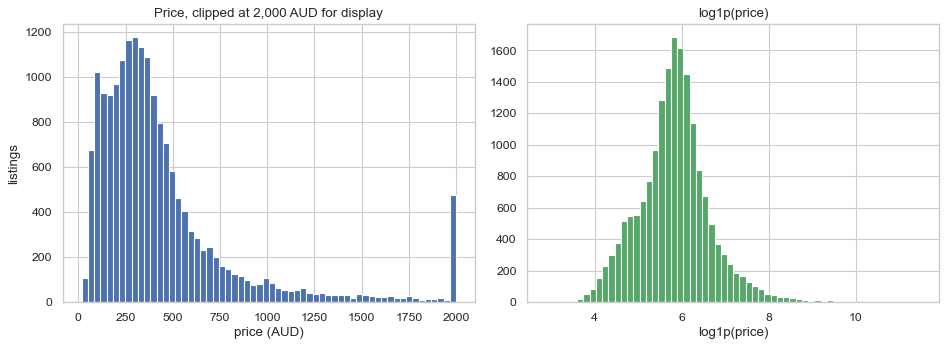


top 20 prices (AUD)
                 id  price_num       room_type  accommodates  bedrooms neighbourhood_cleansed  minimum_nights
1172314473011066918   96887.58 Entire home/apt             6       3.0                 Sydney           100.0
1192424755970639194   96887.58 Entire home/apt             6       3.0                 Sydney           100.0
 948190865551462634   52850.00 Entire home/apt             6       2.0           North Sydney             1.0
 710383936135046292   30642.29 Entire home/apt             8       4.0              Pittwater             1.0
           47554520   19689.81    Private room             2       1.0             Parramatta            90.0
1629358366950479117   19352.29 Entire home/apt            14       7.0              Woollahra             1.0
           23312254   18848.00 Entire home/apt             2       1.0                 Sydney             3.0
1714137576961456831   18814.00 Entire home/apt            10       5.0              Pittwater      

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(usable.clip(upper=2000), bins=60, color="#4C72B0")
axes[0].set_title(f"Price, clipped at 2,000 {CURRENCY} for display")
axes[0].set_xlabel(f"price ({CURRENCY})")
axes[0].set_ylabel("listings")
axes[1].hist(np.log1p(usable), bins=60, color="#55A868")
axes[1].set_title("log1p(price)")
axes[1].set_xlabel("log1p(price)")
fig.tight_layout()
save_figure(fig, "price_distribution")
plt.show()

print(f"\ntop 20 prices ({CURRENCY})")
top20 = (
    listings.loc[price.notna(), ["id", "price_num", "room_type", "accommodates",
                                 "bedrooms", "neighbourhood_cleansed", "minimum_nights"]]
    .sort_values("price_num", ascending=False)
    .head(20)
)
print(top20.to_string(index=False))

## 3. Missingness, empty and constant columns

A column that is entirely missing, or that takes one value, carries no signal
and must be excluded rather than imputed. This is the check that decides
whether `host_verifications`, `instant_bookable` and `host_response_rate` can
be used at all in this download.

In [5]:
profile = pd.DataFrame(
    {
        "dtype": listings.dtypes.astype(str),
        "pct_missing": (100 * listings.isna().mean()).round(2),
        "n_unique": listings.nunique(dropna=True),
    }
)
profile["status"] = np.select(
    [profile["pct_missing"] >= 100.0, profile["n_unique"] <= 1],
    ["empty", "constant"],
    default="",
)
print("missingness for every column, worst first\n")
print(profile.sort_values("pct_missing", ascending=False).to_string())

empty_columns = profile.index[profile["status"] == "empty"].tolist()
constant_columns = profile.index[profile["status"] == "constant"].tolist()
print(f"\nempty columns ({len(empty_columns)}):")
for column in empty_columns:
    print(f"  {column}")
print(f"\nconstant columns ({len(constant_columns)}):")
for column in constant_columns:
    values = listings[column].dropna().unique()[:1]
    print(f"  {column}  value={values}  "
          f"missing={profile.loc[column, 'pct_missing']:.2f}%")

print("\nthe three columns asked about specifically")
for column in ("host_verifications", "instant_bookable", "host_response_rate"):
    if column not in listings.columns:
        print(f"  {column:22s} ABSENT from the schema")
        continue
    print(f"  {column:22s} missing={profile.loc[column, 'pct_missing']:6.2f}%  "
          f"n_unique={profile.loc[column, 'n_unique']}  "
          f"-> {profile.loc[column, 'status'] or 'usable'}")

missingness for every column, worst first

                                                dtype  pct_missing  n_unique    status
neighborhood_overview                         float64       100.00         0     empty
host_thumbnail_url                            float64       100.00         0     empty
host_since                                    float64       100.00         0     empty
host_response_rate                            float64       100.00         0     empty
host_response_time                            float64       100.00         0     empty
host_acceptance_rate                          float64       100.00         0     empty
bathrooms                                     float64       100.00         0     empty
neighbourhood                                 float64       100.00         0     empty
host_verifications                            float64       100.00         0     empty
host_total_listings_count                     float64       100.00         0     empty


## 4. Numeric columns and odd values

Distributions first, then the specific oddities that change a modelling
decision: capacity of zero, bedroom counts of zero, minimum stays longer than
a year, and the extreme upper tails.

The target-leakage family is excluded from every numeric summary here.
`price_quote_price_per_night` is the listed price under another name, and
`estimated_revenue_l365d` is occupancy times price, so either one would let a
model read the answer. The equality is verified rather than assumed.

In [6]:
LEAKAGE_COLUMNS = [
    "estimated_revenue_l365d",
    "price_quote_price_per_night",
    "price_quote_total_price",
    "price_quote_raw",
]
present_leakage = [c for c in LEAKAGE_COLUMNS if c in listings.columns]

print("leakage check against the parsed price")
for column in present_leakage:
    candidate = parse_price(listings[column].astype(str))
    both = price.notna() & candidate.notna()
    if not both.any():
        print(f"  {column:30s} no overlapping non-null rows "
              f"(missing {listings[column].isna().mean():.2%})")
        continue
    identical = np.isclose(candidate[both], price[both]).mean()
    print(f"  {column:30s} overlap={int(both.sum()):,}  "
          f"identical to price in {identical:.2%} of them")
print("\n  -> excluded from all feature work regardless of the overlap")

leakage check against the parsed price


  estimated_revenue_l365d        overlap=17,721  identical to price in 0.00% of them
  price_quote_price_per_night    overlap=17,720  identical to price in 100.00% of them
  price_quote_total_price        overlap=17,720  identical to price in 30.47% of them


  price_quote_raw                no overlapping non-null rows (missing 13.08%)

  -> excluded from all feature work regardless of the overlap


In [7]:
NUMERIC_OF_INTEREST = [
    "accommodates",
    "bedrooms",
    "beds",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "reviews_per_month",
    *REVIEW_SCORE_COLUMNS,
    "calculated_host_listings_count",
    "host_listings_count",
    "hosts_time_as_host_years",
    "hosts_time_as_host_months",
    "latitude",
    "longitude",
]
NUMERIC_OF_INTEREST = [c for c in NUMERIC_OF_INTEREST if c in listings.columns]

numeric = listings[NUMERIC_OF_INTEREST].apply(pd.to_numeric, errors="coerce")
summary = numeric.describe(percentiles=[0.01, 0.5, 0.99]).T.round(3)
summary["pct_missing"] = (100 * numeric.isna().mean()).round(2)
print(summary.to_string())

print("\nodd values")
checks = {
    "accommodates == 0": (numeric["accommodates"] == 0),
    "accommodates >= 16": (numeric["accommodates"] >= 16),
    "bedrooms == 0": (numeric["bedrooms"] == 0),
    "beds == 0": (numeric["beds"] == 0),
    "beds >= 20": (numeric["beds"] >= 20),
    "minimum_nights > 365": (numeric["minimum_nights"] > 365),
    "maximum_nights >= 9999": (numeric["maximum_nights"] >= 9999),
    "availability_365 == 0": (numeric["availability_365"] == 0),
    "availability_365 == 365": (numeric["availability_365"] == 365),
}
for label, mask in checks.items():
    print(f"  {label:26s} {int(mask.sum()):>6,}  ({mask.mean():.2%})")

print("\nrating columns outside the documented 1 to 5 range")
for column in REVIEW_SCORE_COLUMNS:
    values = numeric[column]
    below = int((values < 1).sum())
    above = int((values > 5).sum())
    if below or above:
        print(f"  {column:30s} below 1: {below:>4}   above 5: {above:>4}   "
              f"min={values.min():.2f}  max={values.max():.2f}")

                                  count     mean      std      min       1%      50%       99%       max  pct_missing
accommodates                    20833.0    4.084    2.532    1.000    1.000    4.000    12.000    16.000         0.00
bedrooms                        20811.0    1.857    1.221    0.000    0.000    2.000     5.000    14.000         0.11
beds                            20525.0    2.366    1.699    1.000    1.000    2.000     8.000    50.000         1.48
minimum_nights                  20820.0   15.356   34.331    1.000    1.000    2.000    90.000   500.000         0.06
maximum_nights                  20820.0  512.017  419.060    1.000    7.000  365.000  1125.000  9999.000         0.06
availability_30                 20833.0   12.439   10.535    0.000    0.000   11.000    30.000    30.000         0.00
availability_60                 20833.0   28.173   21.520    0.000    0.000   28.000    60.000    60.000         0.00
availability_90                 20833.0   45.604   32.37

saved reports/figures/numeric_distributions.png


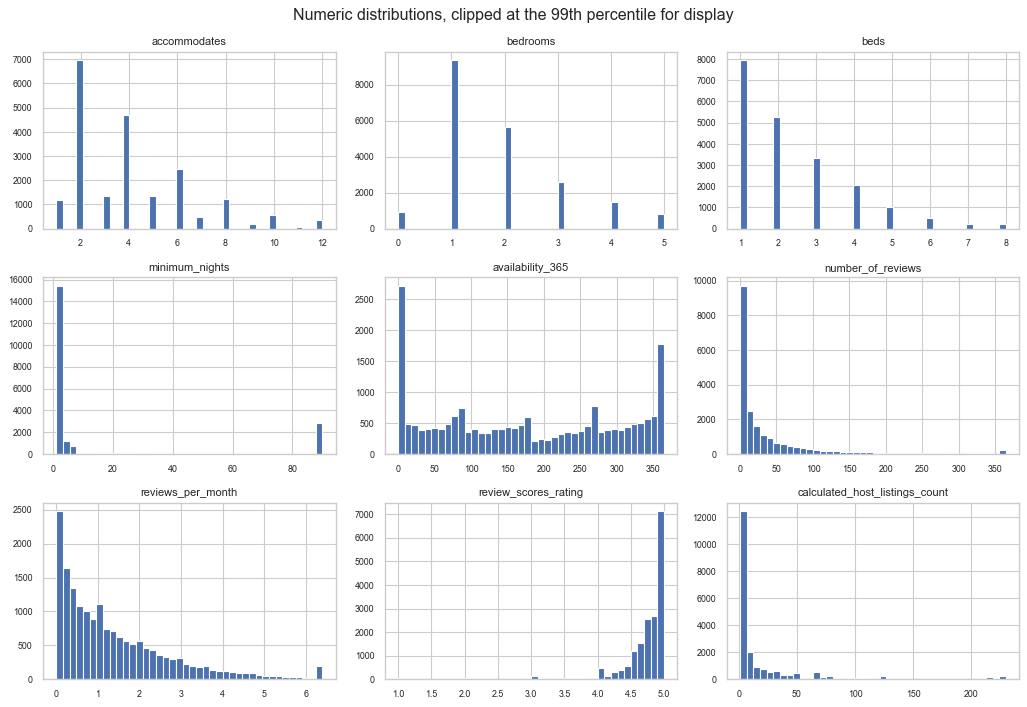

In [8]:
plot_columns = [
    "accommodates",
    "bedrooms",
    "beds",
    "minimum_nights",
    "availability_365",
    "number_of_reviews",
    "reviews_per_month",
    "review_scores_rating",
    "calculated_host_listings_count",
]
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for axis, column in zip(axes.ravel(), plot_columns):
    values = numeric[column].dropna()
    upper = values.quantile(0.99)
    axis.hist(values.clip(upper=upper), bins=40, color="#4C72B0")
    axis.set_title(column, fontsize=10)
    axis.tick_params(labelsize=8)
fig.suptitle("Numeric distributions, clipped at the 99th percentile for display")
fig.tight_layout()
save_figure(fig, "numeric_distributions")
plt.show()

## 5. Categorical columns

Cardinality decides the encoding. `room_type` has four stable levels.
`property_type` nests inside it, so one-hot encoding both produces exactly
collinear blocks, which is why the project keeps `room_type` only.
`neighbourhood_cleansed` is the locality carrier at a cardinality a tree can
handle.

In [9]:
CATEGORICAL_OF_INTEREST = [
    "room_type",
    "property_type",
    "neighbourhood_cleansed",
    "host_identity_verified",
    "host_is_superhost",
    "host_has_profile_pic",
    "has_availability",
    "bathrooms_text",
    "source",
]
CATEGORICAL_OF_INTEREST = [c for c in CATEGORICAL_OF_INTEREST if c in listings.columns]

cardinality = pd.DataFrame(
    {
        "n_unique": [listings[c].nunique(dropna=True) for c in CATEGORICAL_OF_INTEREST],
        "pct_missing": [
            round(100 * listings[c].isna().mean(), 2) for c in CATEGORICAL_OF_INTEREST
        ],
        "top_level": [
            (
                listings[c].value_counts().index[0]
                if listings[c].notna().any()
                else None
            )
            for c in CATEGORICAL_OF_INTEREST
        ],
        "top_share_pct": [
            (
                round(100 * listings[c].value_counts(normalize=True).iloc[0], 2)
                if listings[c].notna().any()
                else None
            )
            for c in CATEGORICAL_OF_INTEREST
        ],
    },
    index=CATEGORICAL_OF_INTEREST,
)
print(cardinality.to_string())

for column in ("room_type", "property_type", "neighbourhood_cleansed"):
    print(f"\ntop levels of {column}")
    print(listings[column].value_counts(dropna=False).head(10).to_string())

print("\nproperty_type nests inside room_type, so they are not independent:")
print(
    pd.crosstab(
        listings["room_type"],
        listings["property_type"].str.split(" in ").str[0].str.split().str[0],
    )
    .iloc[:, :6]
    .to_string()
)

                        n_unique  pct_missing           top_level  top_share_pct
room_type                      4         0.00     Entire home/apt          78.94
property_type                 64         0.00  Entire rental unit          47.07
neighbourhood_cleansed        38         0.00              Sydney          24.12
host_identity_verified         2         0.00                   t          97.45
host_is_superhost              2         0.00                   f          66.51
host_has_profile_pic           2         0.00                   t          97.24
has_availability               2         0.39                   t          99.98
bathrooms_text                34         0.12              1 bath          45.77
source                         1        75.48     previous scrape         100.00

top levels of room_type
room_type
Entire home/apt    16445
Private room        4282
Hotel room            58
Shared room           48

top levels of property_type
property_type
Entire renta

## 6. Price by room type, capacity and neighbourhood

Medians rather than means, because the upper tail drags a mean well above
anything a typical listing charges. The box plots are on the log scale so all
four room types stay readable in one frame.

In [10]:
priced = listings.loc[price > 0].copy()
priced["log_price"] = np.log1p(priced["price_num"])
print(f"priced rows used in this section: {len(priced):,}")

print(f"\nmedian price by room_type ({CURRENCY})")
print(
    priced.groupby("room_type")["price_num"]
    .agg(n="size", median="median", mean="mean", p95=lambda s: s.quantile(0.95))
    .round(2)
    .sort_values("n", ascending=False)
    .to_string()
)

print(f"\nmedian price by accommodates ({CURRENCY})")
print(
    priced.groupby("accommodates")["price_num"]
    .agg(n="size", median="median")
    .round(2)
    .to_string()
)

print(f"\nmedian price by neighbourhood, top and bottom 10 ({CURRENCY})")
by_hood = (
    priced.groupby("neighbourhood_cleansed")["price_num"]
    .agg(n="size", median="median")
    .round(2)
    .sort_values("median", ascending=False)
)
print(pd.concat([by_hood.head(10), by_hood.tail(10)]).to_string())

priced rows used in this section: 17,721

median price by room_type (AUD)
                     n  median    mean      p95
room_type                                      
Entire home/apt  13899  394.00  605.62  1551.01
Private room      3726  124.68  170.61   344.75
Hotel room          53  291.00  294.43   456.00
Shared room         43   66.00   79.73   176.84

median price by accommodates (AUD)
                 n   median
accommodates               
1             1018    99.86
2             5864   220.00
3             1175   280.00
4             3904   378.00
5             1158   419.00
6             2114   506.95
7              407   568.00
8             1051   750.50
9              166   682.00
10             504   807.58
11              48  1033.45
12             157  1032.00
13              27   802.00
14              37  1124.72
15              19   856.00
16              72  1044.75

median price by neighbourhood, top and bottom 10 (AUD)
                           n  median
neigh

saved reports/figures/price_by_roomtype_and_capacity.png


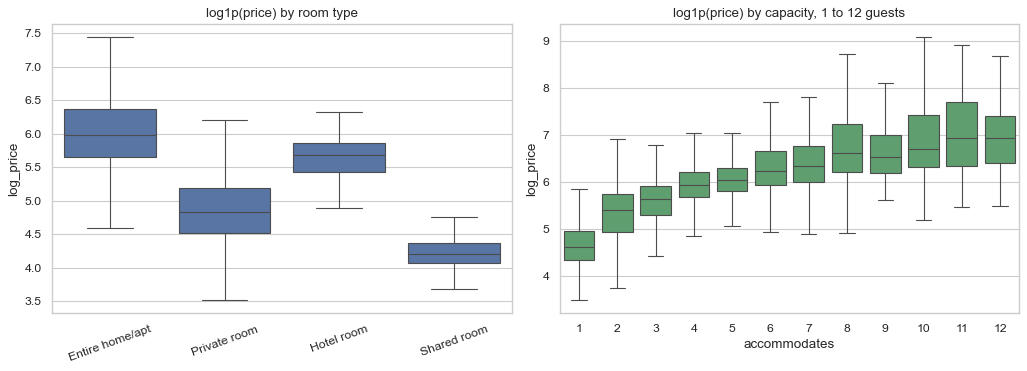

saved reports/figures/median_price_by_neighbourhood.png


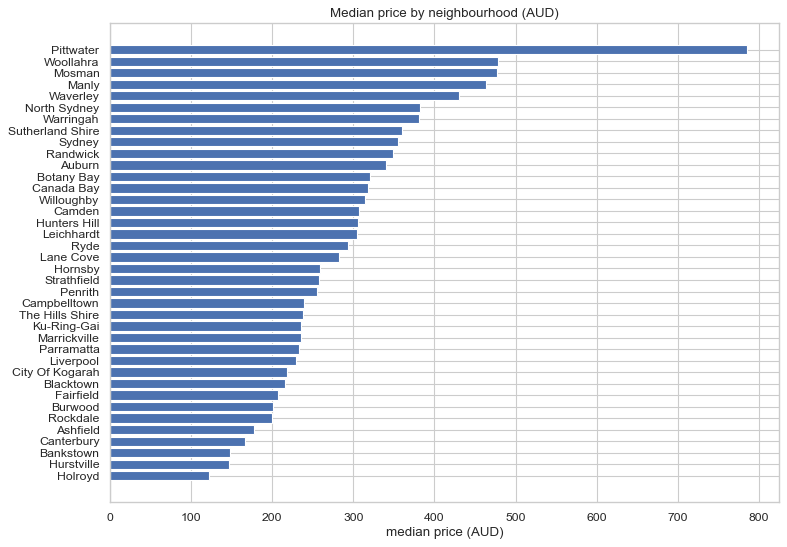

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order = priced["room_type"].value_counts().index
sns.boxplot(data=priced, x="room_type", y="log_price", order=order,
            ax=axes[0], showfliers=False, color="#4C72B0")
axes[0].set_title("log1p(price) by room type")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

capacity = priced.loc[priced["accommodates"] <= 12]
sns.boxplot(data=capacity, x="accommodates", y="log_price",
            ax=axes[1], showfliers=False, color="#55A868")
axes[1].set_title("log1p(price) by capacity, 1 to 12 guests")
fig.tight_layout()
save_figure(fig, "price_by_roomtype_and_capacity")
plt.show()

fig, axis = plt.subplots(figsize=(10, 7))
by_hood_sorted = by_hood.sort_values("median")
axis.barh(by_hood_sorted.index, by_hood_sorted["median"], color="#4C72B0")
axis.set_xlabel(f"median price ({CURRENCY})")
axis.set_title(f"Median price by neighbourhood ({CURRENCY})")
fig.tight_layout()
save_figure(fig, "median_price_by_neighbourhood")
plt.show()

## 7. Geography and distance to the CBD

Coordinates are explored here but are **not** kept as model features. A mentor
has no latitude, and a tree splitting on raw coordinates memorises the street
grid rather than learning a market effect. The distance to the CBD is the
transferable form of the same signal, and in the app it will be replaced by a
neighbourhood centroid, so locality survives without the mentor supplying a
coordinate.

Distance uses the haversine formula against the Sydney CBD at
(-33.8688, 151.2093).

count    17721.00
mean        11.41
std         10.72
min          0.10
25%          3.42
50%          7.37
75%         15.70
max         58.05


saved reports/figures/geography_and_cbd_distance.png


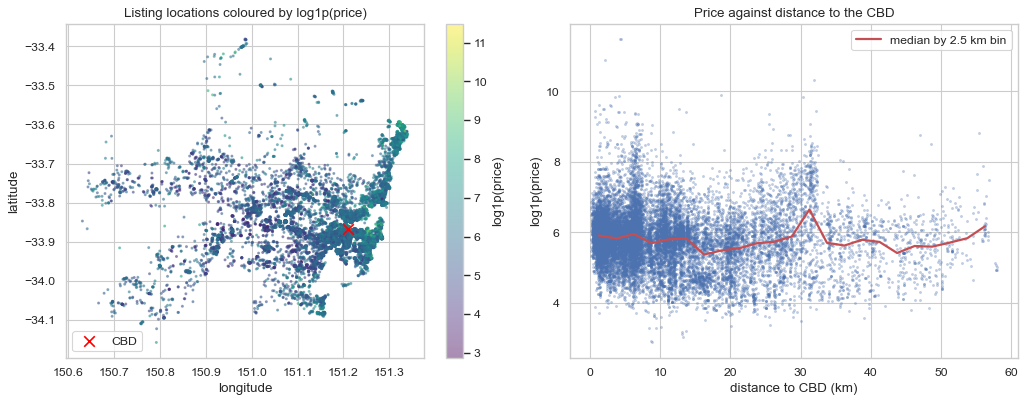


Spearman correlation, distance to CBD vs log price: -0.1239

median price (AUD) by distance band
                    n  median
distance_cbd_km              
(0.0, 2.0]       2839  369.00
(2.0, 5.0]       3068  348.16
(5.0, 10.0]      4204  355.75
(10.0, 20.0]     4354  302.75
(20.0, 40.0]     2783  318.50
(40.0, inf]       473  298.00


In [12]:
CBD_LAT, CBD_LON = -33.8688, 151.2093
EARTH_RADIUS_KM = 6371.0088


def haversine_km(lat, lon, lat0=CBD_LAT, lon0=CBD_LON):
    """Great-circle distance in km from each (lat, lon) to a fixed point."""
    lat, lon = np.radians(np.asarray(lat, dtype=float)), np.radians(
        np.asarray(lon, dtype=float)
    )
    lat0, lon0 = np.radians(lat0), np.radians(lon0)
    half_dlat = (lat - lat0) / 2.0
    half_dlon = (lon - lon0) / 2.0
    inner = (
        np.sin(half_dlat) ** 2
        + np.cos(lat) * np.cos(lat0) * np.sin(half_dlon) ** 2
    )
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(inner))


priced["distance_cbd_km"] = haversine_km(priced["latitude"], priced["longitude"])
print(priced["distance_cbd_km"].describe().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
points = axes[0].scatter(
    priced["longitude"], priced["latitude"], c=priced["log_price"],
    s=3, alpha=0.45, cmap="viridis", rasterized=True,
)
axes[0].scatter([CBD_LON], [CBD_LAT], marker="x", s=90, c="red", label="CBD")
axes[0].set_xlabel("longitude")
axes[0].set_ylabel("latitude")
axes[0].set_title("Listing locations coloured by log1p(price)")
axes[0].legend(loc="lower left")
fig.colorbar(points, ax=axes[0], label="log1p(price)")

axes[1].scatter(priced["distance_cbd_km"], priced["log_price"],
                s=3, alpha=0.25, color="#4C72B0", rasterized=True)
binned = priced.groupby(pd.cut(priced["distance_cbd_km"], bins=np.arange(0, 60, 2.5)),
                        observed=False)["log_price"].median()
centres = [interval.mid for interval in binned.index]
axes[1].plot(centres, binned.to_numpy(), color="#C44E52", lw=2, label="median by 2.5 km bin")
axes[1].set_xlabel("distance to CBD (km)")
axes[1].set_ylabel("log1p(price)")
axes[1].set_title("Price against distance to the CBD")
axes[1].legend()
fig.tight_layout()
save_figure(fig, "geography_and_cbd_distance")
plt.show()

print(f"\nSpearman correlation, distance to CBD vs log price: "
      f"{priced['distance_cbd_km'].corr(priced['log_price'], method='spearman'):.4f}")
print(f"\nmedian price ({CURRENCY}) by distance band")
print(
    priced.groupby(pd.cut(priced["distance_cbd_km"], [0, 2, 5, 10, 20, 40, np.inf]),
                   observed=False)["price_num"]
    .agg(n="size", median="median")
    .round(2)
    .to_string()
)

## 8. Correlation with log price, and collinear pairs

Spearman rather than Pearson, because most of these columns are counts with
long tails and the relationship with price is monotone rather than linear.

The second table matters for Ridge, which is one of the three candidate
models. Pairs correlated above 0.9 with each other carry nearly the same
information, and a linear model splits large offsetting coefficients between
them.

Spearman correlation with log1p(price)
accommodates                      0.7137
bedrooms                          0.6678
beds                              0.6474
review_scores_location            0.3281
review_scores_rating              0.2301
review_scores_accuracy            0.2041
review_scores_cleanliness         0.1809
review_scores_communication       0.1789
review_scores_checkin             0.1546
availability_30                  -0.1354
distance_cbd_km                  -0.1239
availability_60                  -0.1236
availability_90                  -0.1180
review_scores_value               0.0855
number_of_reviews                -0.0635
hosts_time_as_host_months         0.0617
hosts_time_as_host_years          0.0601
host_listings_count               0.0554
reviews_per_month                -0.0542
number_of_reviews_ltm            -0.0372
calculated_host_listings_count    0.0365
number_of_reviews_l30d           -0.0360
availability_365                 -0.0346
minimum_nights    


pairs correlated at 0.9 or above (4)
                      column_a            column_b  spearman
calculated_host_listings_count host_listings_count    0.9708
               availability_60     availability_90    0.9696
               availability_30     availability_60    0.9214
                  accommodates                beds    0.9056


saved reports/figures/numeric_correlation_heatmap.png


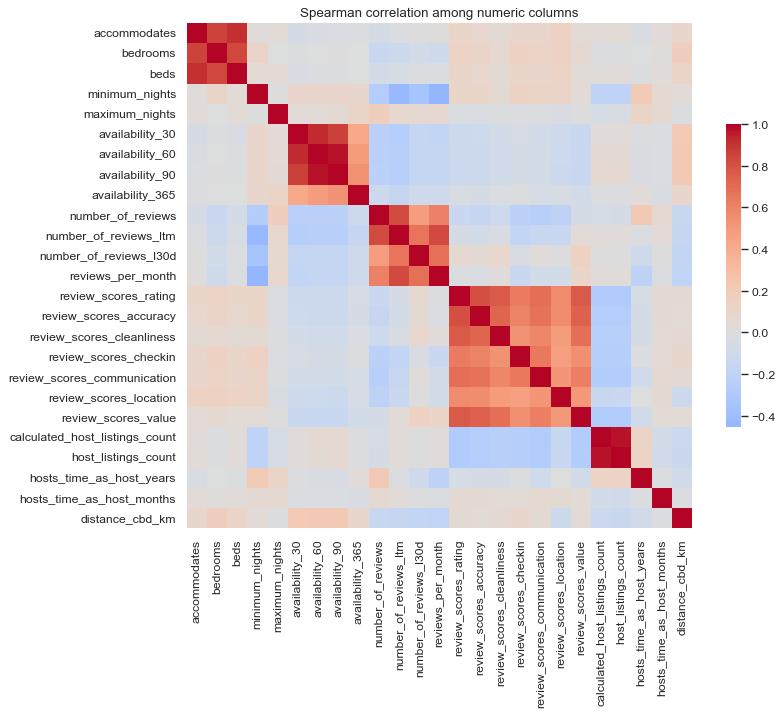

In [13]:
correlation_columns = [c for c in NUMERIC_OF_INTEREST if c not in ("latitude", "longitude")]
correlation_frame = priced[correlation_columns].apply(pd.to_numeric, errors="coerce")
correlation_frame["distance_cbd_km"] = priced["distance_cbd_km"]

with_target = (
    correlation_frame.corrwith(priced["log_price"], method="spearman")
    .sort_values(key=np.abs, ascending=False)
    .round(4)
)
print("Spearman correlation with log1p(price)")
print(with_target.to_string())

matrix = correlation_frame.corr(method="spearman")
pairs = (
    matrix.where(np.triu(np.ones(matrix.shape), k=1).astype(bool))
    .stack()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "column_a", "level_1": "column_b"})
)
strong = pairs.loc[pairs["spearman"].abs() >= 0.9].sort_values(
    "spearman", key=np.abs, ascending=False
)
print(f"\npairs correlated at 0.9 or above ({len(strong)})")
print(strong.round(4).to_string(index=False))

fig, axis = plt.subplots(figsize=(11, 9))
sns.heatmap(matrix, cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.6}, ax=axis)
axis.set_title("Spearman correlation among numeric columns")
fig.tight_layout()
save_figure(fig, "numeric_correlation_heatmap")
plt.show()

## 9. Derived parses: amenities, bathrooms, host tenure

Three columns need parsing before they are usable, and each has a wrinkle in
this download.

- **amenities** is a JSON list. As a raw string it has thousands of distinct
  values and is useless as a category; as a length it is informative.
- **bathrooms** is fully empty in this download, so the count has to come from
  `bathrooms_text`. That column mixes numbers with words: `"1 bath"`,
  `"1.5 shared baths"`, `"Half-bath"`, `"No bathroom"`. Half-baths map to 0.5
  and `"No bathroom"` to 0. Rows that still cannot be parsed stay NaN rather
  than being filled, because filling is a training-split decision.
- **host_since** is also fully empty, so tenure comes from
  `hosts_time_as_host_years` plus `hosts_time_as_host_months / 12`. These are
  already measured at the snapshot date by the scraper, which keeps rule 3
  intact: no window is anchored to today.

In [14]:
def amenities_count(values: pd.Series) -> pd.Series:
    """Length of the JSON amenity list, NaN when it cannot be parsed."""

    def count(raw):
        if not isinstance(raw, str) or not raw.strip():
            return np.nan
        try:
            parsed = json.loads(raw)
        except (json.JSONDecodeError, ValueError):
            return float(len([p for p in raw.strip("{}[]").split(",") if p.strip()]))
        return float(len(parsed)) if isinstance(parsed, list) else np.nan

    return values.map(count).astype(np.float64)


def bathrooms_from_text(values: pd.Series) -> pd.Series:
    """Bathroom count from the free-text column; NaN when unparseable."""
    text = values.astype("string").str.strip().str.lower()
    numeric = pd.to_numeric(
        text.str.extract(r"(\d+\.?\d*)", expand=False), errors="coerce"
    ).astype("float64")
    numeric = numeric.mask(text.str.contains("half-bath", na=False), 0.5)
    numeric = numeric.mask(text.eq("no bathroom"), 0.0)
    return numeric.where(text.notna(), np.nan)


derived = pd.DataFrame(index=listings.index)
derived["amenities_count"] = amenities_count(listings["amenities"])
derived["bathrooms_parsed"] = bathrooms_from_text(listings["bathrooms_text"])
derived["host_tenure_years"] = pd.to_numeric(
    listings["hosts_time_as_host_years"], errors="coerce"
) + pd.to_numeric(listings["hosts_time_as_host_months"], errors="coerce") / 12.0

print("amenities_count")
print(derived["amenities_count"].describe().round(2).to_string())
print(f"  unparseable: {int(derived['amenities_count'].isna().sum()):,}")

print("\nbathrooms_parsed")
print(derived["bathrooms_parsed"].describe().round(2).to_string())
print(f"  raw bathrooms column missing : {listings['bathrooms'].isna().mean():.2%}")
print(f"  bathrooms_text missing       : {listings['bathrooms_text'].isna().mean():.2%}")
print(f"  parsed still missing         : {derived['bathrooms_parsed'].isna().mean():.2%}")
print("\n  text levels that did not parse to a number:")
unparsed = listings.loc[
    derived["bathrooms_parsed"].isna() & listings["bathrooms_text"].notna(),
    "bathrooms_text",
]
print("   ", unparsed.value_counts().to_dict() or "none")
print("\n  spot check of the parse")
print(
    pd.DataFrame({"text": listings["bathrooms_text"], "parsed": derived["bathrooms_parsed"]})
    .drop_duplicates("text")
    .sort_values("parsed")
    .head(12)
    .to_string(index=False)
)

print("\nhost_tenure_years")
print(derived["host_tenure_years"].describe().round(2).to_string())
print(f"  host_since column missing: {listings['host_since'].isna().mean():.2%} "
      f"(so tenure comes from the scraper's year and month fields)")

amenities_count
count    20833.00
mean        37.69
std         15.77
min          0.00
25%         28.00
50%         39.00
75%         49.00
max        119.00
  unparseable: 0

bathrooms_parsed
count    20809.00
mean         1.50
std          0.82
min          0.00
25%          1.00
50%          1.00
75%          2.00
max         21.00
  raw bathrooms column missing : 100.00%
  bathrooms_text missing       : 0.12%
  parsed still missing         : 0.12%

  text levels that did not parse to a number:
    none

  spot check of the parse
             text  parsed
   0 shared baths     0.0
          0 baths     0.0
      No bathroom     0.0
 Shared half-bath     0.5
        Half-bath     0.5
Private half-bath     0.5
           1 bath     1.0
    1 shared bath     1.0
   1 private bath     1.0
        1.5 baths     1.5
 1.5 shared baths     1.5
          2 baths     2.0

host_tenure_years
count    20832.00
mean         6.00
std          4.10
min          0.00
25%          2.25
50%         

## 10. Data quality issues and proposed actions

Every issue found above, with the action notebook 03 takes. Actions that would
require a fitted statistic are deferred by design, not forgotten.

In [15]:
ISSUES = [
    ("price missing on some listings",
     f"{int(price.isna().sum()):,} rows ({price.isna().mean():.2%})",
     "drop from the master dataset and report the count; a listing with no "
     "price is inactive, not randomly missing"),
    ("price has a very long upper tail",
     f"max {usable.max():,.2f} {CURRENCY}, 99th pct {usable.quantile(0.99):,.2f}",
     "keep every row in the master; fit on log1p(price) and decide fences on "
     "the training split later"),
    ("bathrooms column is entirely empty",
     "100% missing",
     "parse bathrooms_text instead; leave NaN where the text is missing too"),
    ("host_since is entirely empty",
     "100% missing",
     "derive host_tenure_years from hosts_time_as_host_years and _months"),
    ("host_verifications, instant_bookable, host_response_rate are empty",
     "100% missing each",
     "exclude from the master dataset; a constant column cannot be a feature"),
    ("rating columns exceed the documented 1 to 5 range",
     "several review_scores_* reach 5.1 to 5.5 and some sit at 0",
     "keep as-is and record the observed range in the data dictionary; do not "
     "clip, since clipping is a modelling choice"),
    ("bedrooms == 0 on many listings",
     f"{int((listings['bedrooms'] == 0).sum()):,} rows",
     "keep; 0 is meaningful for a studio, it is not a missing value"),
    ("minimum_nights far above a year",
     f"{int((pd.to_numeric(listings['minimum_nights'], errors='coerce') > 365).sum()):,} rows above 365",
     "keep in the master and flag; these are effectively long-term rentals and "
     "may deserve exclusion at modelling time"),
    ("maximum_nights sentinel value",
     f"{int((pd.to_numeric(listings['maximum_nights'], errors='coerce') >= 9999).sum()):,} rows at 9999 or more",
     "not used as a feature; 9999 is a 'no limit' sentinel, not a duration"),
    ("property_type nests inside room_type",
     f"{listings['property_type'].nunique()} levels against 4",
     "keep room_type only, as src/config.py already documents"),
    ("target leakage family present in the schema",
     ", ".join(present_leakage),
     "excluded from every feature list; price_quote_price_per_night is the "
     "listed price under another name"),
    ("latitude and longitude are exact coordinates",
     "0% missing, 15k distinct values",
     "tagged drop for the app; locality is carried by neighbourhood_cleansed "
     "and will be replaced by a neighbourhood centroid"),
    ("source column is constant where present",
     f"one value, {listings['source'].isna().mean():.2%} missing",
     "not used; it records scrape provenance, not a listing attribute"),
]

issues = pd.DataFrame(ISSUES, columns=["issue", "evidence", "proposed action"])
for row in issues.itertuples(index=False):
    print(f"- {row.issue}")
    print(f"    evidence : {row.evidence}")
    print(f"    action   : {row._2}")

print(f"\n{len(issues)} issues recorded")
print("\nfigures written to reports/figures/:")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(f"  {path.name}  ({path.stat().st_size / 1024:.0f} KB)")

- price missing on some listings
    evidence : 3,112 rows (14.94%)
    action   : drop from the master dataset and report the count; a listing with no price is inactive, not randomly missing
- price has a very long upper tail
    evidence : max 96,887.58 AUD, 99th pct 3,481.69
    action   : keep every row in the master; fit on log1p(price) and decide fences on the training split later
- bathrooms column is entirely empty
    evidence : 100% missing
    action   : parse bathrooms_text instead; leave NaN where the text is missing too
- host_since is entirely empty
    evidence : 100% missing
    action   : derive host_tenure_years from hosts_time_as_host_years and _months
- host_verifications, instant_bookable, host_response_rate are empty
    evidence : 100% missing each
    action   : exclude from the master dataset; a constant column cannot be a feature
- rating columns exceed the documented 1 to 5 range
    evidence : several review_scores_* reach 5.1 to 5.5 and some sit at 0
    a